<a href="https://colab.research.google.com/github/JorgeLuisMadrid/Aprendizaje-Maquina-2026B/blob/main/L06_Red_Neuronal_LoanPrediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Red Neuronal Densa: Predicción de Aprobación de Préstamos
Dataset: `loan_prediction.csv` — variable de interés: `Loan_Status`.

## 1. Exploración del conjunto de datos y sus variables

Paso 1. Importamos la paquetería necesaria.

In [1]:
# Paquetería básica
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TensorFlow y Keras
import tensorflow as tf
from tensorflow import keras

# Utilidades de Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report,
                              roc_auc_score, roc_curve)

# Paleta de colores consistente para todas las gráficas
COLOR_TRAIN = '#2a78d6'   # azul
COLOR_VAL   = '#eb6834'   # naranja
COLOR_AUX   = '#1baf7a'   # aqua

np.random.seed(42)
tf.random.set_seed(42)

/Users/jorgeluismadrid/Documents/AM/Aprendizaje-Maquina-2026B/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Paso 2. Descargamos y cargamos el dataset.

In [2]:
!rm -f "loan_prediction.csv"
!wget -q "https://raw.githubusercontent.com/JorgeLuisMadrid/Aprendizaje-Maquina-2026B/main/Datasets/loan_prediction.csv" -O "loan_prediction.csv"

dataset = pd.read_csv("loan_prediction.csv")
dataset.head()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status
0,5849,0.0,0.0,360.0,1.0,1
1,4583,1508.0,128.0,360.0,1.0,0
2,3000,0.0,66.0,360.0,1.0,1
3,2583,2358.0,120.0,360.0,1.0,1
4,6000,0.0,141.0,360.0,1.0,1


Paso 3. Exploramos la estructura, los tipos de dato y las estadísticas descriptivas.

In [3]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ApplicantIncome    614 non-null    int64  
 1   CoapplicantIncome  614 non-null    float64
 2   LoanAmount         614 non-null    float64
 3   Loan_Amount_Term   614 non-null    float64
 4   Credit_History     614 non-null    float64
 5   Loan_Status        614 non-null    int64  
dtypes: float64(4), int64(2)
memory usage: 28.9 KB


In [4]:
dataset.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status
count,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000
mean,5403.459283,1621.245798,141.166124,334.201954,0.773616,0.687296
std,6109.041673,2926.248369,88.340630,82.183884,0.418832,0.463973
min,150.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2877.500000,0.000000,98.000000,360.000000,1.000000,0.000000
50%,3812.500000,1188.500000,125.000000,360.000000,1.000000,1.000000
75%,5795.000000,2297.250000,164.750000,360.000000,1.000000,1.000000
max,81000.000000,41667.000000,700.000000,480.000000,1.000000,1.000000


Revisamos el balance de clases de la variable de interés.

Loan_Status
1    422
0    192
Name: count, dtype: int64


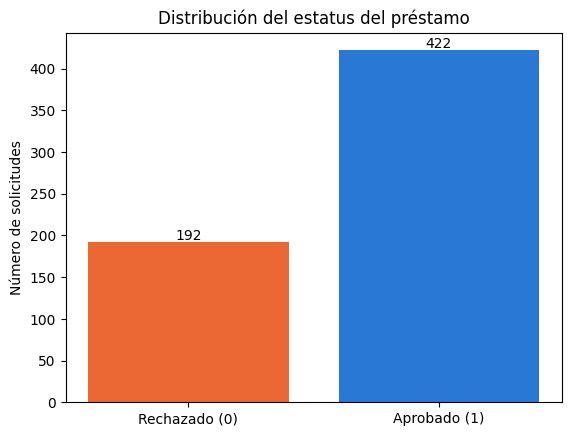

In [5]:
conteo = dataset['Loan_Status'].value_counts()
print(conteo)

plt.figure()
plt.bar(['Rechazado (0)', 'Aprobado (1)'], conteo.sort_index().values,
        color=[COLOR_VAL, COLOR_TRAIN])
plt.title('Distribución del estatus del préstamo')
plt.ylabel('Número de solicitudes')
for i, v in enumerate(conteo.sort_index().values):
    plt.text(i, v + 3, str(v), ha='center')
plt.show()

## 2. Limpieza del conjunto de datos y codificación de variables

Paso 4. Revisamos valores faltantes y duplicados, y eliminamos las filas duplicadas. Todas las columnas de este conjunto ya son numéricas, por lo que no se requiere codificar variables categóricas.

In [6]:
print('Valores faltantes por columna:')
print(dataset.isna().sum())
print()
print('Filas duplicadas:', dataset.duplicated().sum())

dataset = dataset.drop_duplicates().reset_index(drop=True)
print('Forma del dataset tras eliminar duplicados:', dataset.shape)
print()
print(dataset.dtypes)

Valores faltantes por columna:
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Loan_Status          0
dtype: int64

Filas duplicadas: 1
Forma del dataset tras eliminar duplicados: (613, 6)

ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Loan_Status            int64
dtype: object


## 3. Variables de entrada y variable de salida

Paso 5. La variable de salida es `Loan_Status`; el resto de las columnas son las variables de entrada.

In [7]:
x = np.asanyarray(dataset.drop(columns=['Loan_Status']))
y = np.asanyarray(dataset[['Loan_Status']])
print(x.shape)
print(y.shape)

(613, 5)
(613, 1)


## 4. Normalización y partición del conjunto de datos

Paso 6. Estandarizamos las variables de entrada y particionamos en entrenamiento (80%) y prueba (20%), manteniendo la proporción de clases con `stratify`.

In [8]:
scaler_x = StandardScaler()
x = scaler_x.fit_transform(x)

xtrain, xtest, ytrain, ytest = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y)

print(xtrain.shape, xtest.shape)

(490, 5) (123, 5)


## 5. Diseño de la red neuronal

Paso 7. Diseñamos una red densa con dos capas ocultas para la clasificación binaria, con `Dropout` como regularización y una neurona de salida con activación `sigmoid`.

In [9]:
def build_model(n_inputs, hidden1=32, hidden2=16, dropout=0.3, lr=1e-3):
    model = keras.Sequential()
    model.add(keras.layers.Dense(hidden1, activation='relu', input_shape=[n_inputs]))
    model.add(keras.layers.Dropout(dropout))
    model.add(keras.layers.Dense(hidden2, activation='relu'))
    model.add(keras.layers.Dense(1, activation='sigmoid'))

    model.compile(loss='binary_crossentropy',
                  optimizer=keras.optimizers.Adam(learning_rate=lr),
                  metrics=['accuracy', keras.metrics.AUC(name='auc')])
    return model

model = build_model(x.shape[1])
model.summary()

/Users/jorgeluismadrid/Documents/AM/Aprendizaje-Maquina-2026B/.venv/lib/python3.9/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 737 (2.88 KB)

 Trainable params: 737 (2.88 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Entrenamiento de la red y curvas de aprendizaje

Paso 8. Entrenamos la red con los hiperparámetros base.

In [10]:
history = model.fit(xtrain, ytrain,
                     batch_size=32, epochs=100,
                     validation_data=(xtest, ytest), verbose=0)
print('Última pérdida de validación:', history.history['val_loss'][-1])

Última pérdida de validación: 0.5022167563438416


Paso 9. Graficamos la evolución del entrenamiento a través de las épocas.

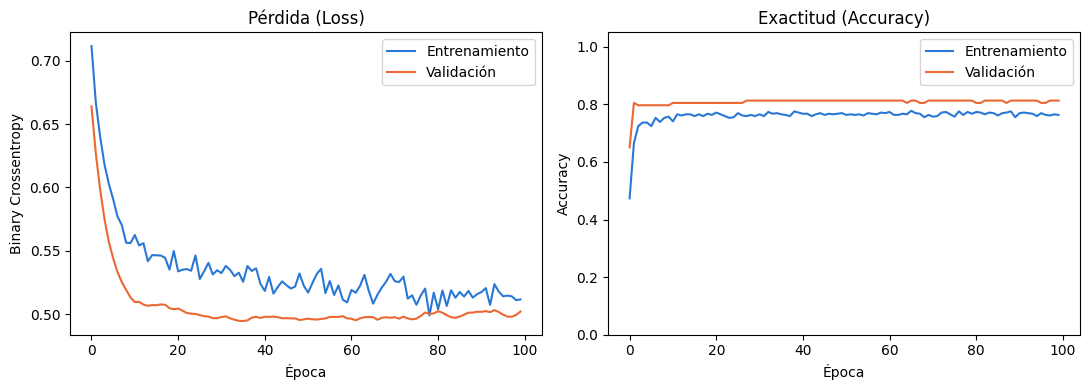

In [11]:
def plot_history(history):
    hist = pd.DataFrame(history.history)
    hist['epoch'] = history.epoch

    plt.figure(figsize=(11, 4))

    plt.subplot(1, 2, 1)
    plt.title('Pérdida (Loss)')
    plt.xlabel('Época')
    plt.ylabel('Binary Crossentropy')
    plt.plot(hist['epoch'], hist['loss'], color=COLOR_TRAIN, label='Entrenamiento')
    plt.plot(hist['epoch'], hist['val_loss'], color=COLOR_VAL, label='Validación')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.title('Exactitud (Accuracy)')
    plt.xlabel('Época')
    plt.ylabel('Accuracy')
    plt.plot(hist['epoch'], hist['accuracy'], color=COLOR_TRAIN, label='Entrenamiento')
    plt.plot(hist['epoch'], hist['val_accuracy'], color=COLOR_VAL, label='Validación')
    plt.ylim([0, 1.05])
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(history)

## 7. Búsqueda de hiperparámetros

Paso 10. Las clases están desbalanceadas (más préstamos aprobados que rechazados), así que además de probar distintas arquitecturas, calculamos pesos por clase (`class_weight`) para que la red no ignore la clase minoritaria. Entrenamos cada combinación con `EarlyStopping` y comparamos el desempeño sobre el conjunto de validación.

In [12]:
class_weights = compute_class_weight('balanced', classes=np.unique(ytrain), y=ytrain.ravel())
class_weight_dict = {0: class_weights[0], 1: class_weights[1]}
print('Pesos por clase:', class_weight_dict)

configs = [
    dict(hidden1=16, hidden2=8, dropout=0.2, lr=1e-3),
    dict(hidden1=32, hidden2=16, dropout=0.3, lr=1e-3),
    dict(hidden1=32, hidden2=16, dropout=0.4, lr=5e-4),
    dict(hidden1=64, hidden2=32, dropout=0.3, lr=1e-3),
    dict(hidden1=64, hidden2=32, dropout=0.5, lr=5e-4),
]

resultados = []
for cfg in configs:
    es = keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=10,
                                        restore_best_weights=True)
    m = build_model(x.shape[1], **cfg)
    h = m.fit(xtrain, ytrain, batch_size=32, epochs=150,
              validation_data=(xtest, ytest), verbose=0, callbacks=[es],
              class_weight=class_weight_dict)
    val_loss = min(h.history['val_loss'])
    val_auc = max(h.history['val_auc'])
    resultados.append({**cfg, 'val_loss': val_loss, 'val_auc': val_auc,
                        'epochs_entrenadas': len(h.epoch)})

resultados_df = pd.DataFrame(resultados).sort_values('val_auc', ascending=False)
resultados_df

Pesos por clase: {0: np.float64(1.6013071895424837), 1: np.float64(0.7270029673590505)}


/Users/jorgeluismadrid/Documents/AM/Aprendizaje-Maquina-2026B/.venv/lib/python3.9/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


,hidden1,hidden2,dropout,lr,val_loss,val_auc,epochs_entrenadas
4,64,32,0.5,0.0005,0.549648,0.781424,44
2,32,16,0.4,0.0005,0.546177,0.776780,63
3,64,32,0.3,0.0010,0.530998,0.776780,81
0,16,8,0.2,0.0010,0.558759,0.759288,62
1,32,16,0.3,0.0010,0.546427,0.759288,55


Paso 11. Reentrenamos el modelo final con la mejor combinación de hiperparámetros encontrada.

Mejores hiperparámetros encontrados: {'hidden1': 64, 'hidden2': 32, 'dropout': np.float64(0.5), 'lr': np.float64(0.0005)}


/Users/jorgeluismadrid/Documents/AM/Aprendizaje-Maquina-2026B/.venv/lib/python3.9/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


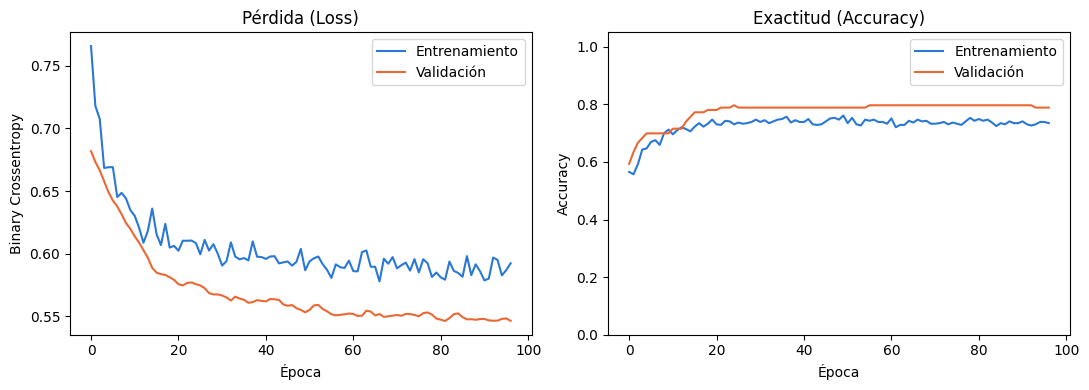

In [13]:
best_cfg = {k: resultados_df.iloc[0][k] for k in ['hidden1', 'hidden2', 'dropout', 'lr']}
best_cfg['hidden1'] = int(best_cfg['hidden1'])
best_cfg['hidden2'] = int(best_cfg['hidden2'])
print('Mejores hiperparámetros encontrados:', best_cfg)

es = keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=15,
                                    restore_best_weights=True)
final_model = build_model(x.shape[1], **best_cfg)
history_final = final_model.fit(xtrain, ytrain, batch_size=32, epochs=200,
                                 validation_data=(xtest, ytest), verbose=0,
                                 callbacks=[es], class_weight=class_weight_dict)
plot_history(history_final)

## 8. Métricas de desempeño

Paso 12. Calculamos las métricas de clasificación sobre el conjunto de prueba.

In [14]:
y_prob = final_model.predict(xtest, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print('Accuracy :', accuracy_score(ytest, y_pred))
print('Precision:', precision_score(ytest, y_pred))
print('Recall   :', recall_score(ytest, y_pred))
print('F1-score :', f1_score(ytest, y_pred))
print('ROC-AUC  :', roc_auc_score(ytest, y_prob))
print()
print(classification_report(ytest, y_pred, target_names=['Rechazado', 'Aprobado']))

Accuracy : 0.7967479674796748
Precision: 0.8409090909090909
Recall   : 0.8705882352941177
F1-score : 0.8554913294797688
ROC-AUC  : 0.7613003095975233

              precision    recall  f1-score   support

   Rechazado       0.69      0.63      0.66        38
    Aprobado       0.84      0.87      0.86        85

    accuracy                           0.80       123
   macro avg       0.76      0.75      0.76       123
weighted avg       0.79      0.80      0.79       123



Paso 13. Visualizamos la matriz de confusión y la curva ROC.

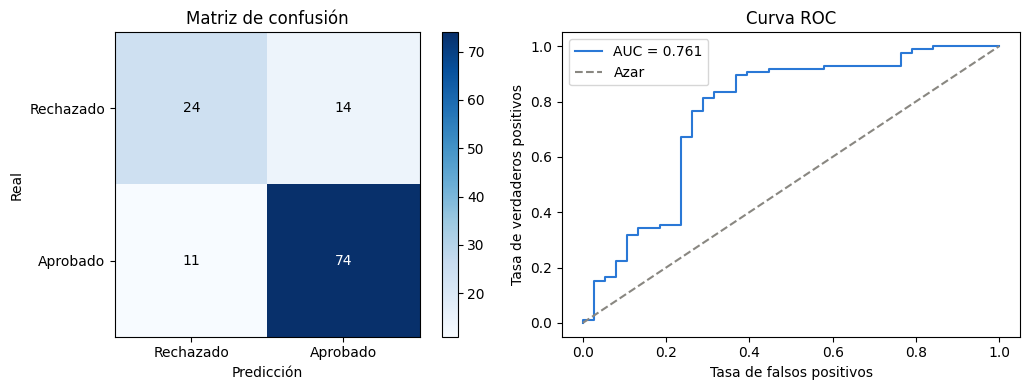

In [15]:
cm = confusion_matrix(ytest, y_pred)
fpr, tpr, _ = roc_curve(ytest, y_prob)

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.imshow(cm, cmap='Blues')
plt.title('Matriz de confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.xticks([0, 1], ['Rechazado', 'Aprobado'])
plt.yticks([0, 1], ['Rechazado', 'Aprobado'])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                  color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.colorbar()

plt.subplot(1, 2, 2)
plt.plot(fpr, tpr, color=COLOR_TRAIN, label=f'AUC = {roc_auc_score(ytest, y_prob):.3f}')
plt.plot([0, 1], [0, 1], '--', color='#898781', label='Azar')
plt.title('Curva ROC')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.legend()

plt.tight_layout()
plt.show()